# Path Generation: Speed, Memory, and Hedging

We keep the three-stock market and network from `Large_Portfoloio_Comparison.ipynb`.
We compare Regular/Fast generation with fixed-pool/fresh-batch training.
First we create equal numbers of scenarios; then we measure complete training runs.

Run this notebook from the repository root using the included `scripts/` modules.
Start with `QUICK_RUN=True`; switch to `False` for the full experiment.
Existing notebooks continue using Regular generation by default.

In [1]:
from dataclasses import replace
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, SVG, display

from scripts.general_nn import generalNN
from scripts.settings import NetworkSettings, Settings, StockSettings

from scripts.memory_tracker import run_memory_experiment
from scripts.path_benchmark import run_path_benchmark

## Settings

`QUICK_RUN=True` uses a smaller initial experiment. Set it to `False` to use the
large notebook's original training and dataset sizes. Both profiles preserve
30 daily time steps, 64 simulation substeps, all three stocks and the same network.
Repeats vary training and initialization seeds; validation/test seeds stay fixed.

In [2]:
QUICK_RUN = True
REPEATS = 3
FAST_WORKERS = 6
PREFETCH_BATCHES = 2

# Original large-portfolio settings.
settings = Settings(
    warmup_updates=100,
    continuation_updates=1000,
    number_of_replicates=1,
    validation_interval=50,
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,
    static_training_size=2**18,
)

if QUICK_RUN:
    settings = replace(
        settings,
        warmup_updates=10,
        continuation_updates=25,
        validation_interval=5,
        normalization_size=512,
        validation_size=1024,
        test_size=2048,
        static_training_size=8192,
    )

assert type(REPEATS) is int and REPEATS >= 1
generation_paths = settings.static_training_size
assert generation_paths % settings.batch_size == 0
profile = "quick" if QUICK_RUN else "full"
result_dir = Path("results/path_generation_comparison") / profile
result_dir.mkdir(parents=True, exist_ok=True)

print(f"Profile: {profile}; repeats: {REPEATS}; generation scenarios per run: {generation_paths:,}")
print(f"Warmup updates: {settings.warmup_updates}; continuation updates per objective: {settings.continuation_updates}")

Profile: quick; repeats: 3; generation scenarios per run: 8,192
Warmup updates: 10; continuation updates per objective: 25


## Market and four configurations

One scenario contains paths for all three stocks and their variance claims.
All four cases use one identical model preset, architecture and instruments.
Only the generator and the fixed/fresh data mode change.

In [3]:
stocks_list = [
    StockSettings(name="Stock1", initial_price=100.0, strike=100.0,
                  initial_variance=0.04, long_run_variance=0.04,
                  mean_reversion=1.0, vol_of_vol=2.0, correlation=-0.7),
    StockSettings(name="Stock2", initial_price=50.0, strike=50.0,
                  initial_variance=0.02, long_run_variance=0.02,
                  mean_reversion=1.2, vol_of_vol=1.8, correlation=-0.6),
    StockSettings(name="Stock3", initial_price=200.0, strike=200.0,
                  initial_variance=0.06, long_run_variance=0.06,
                  mean_reversion=0.8, vol_of_vol=2.2, correlation=-0.5),
]

In [4]:
n_stocks = len(stocks_list)

network = NetworkSettings(
    hidden_sizes=(12 * n_stocks, 12 * n_stocks),
    activation="tanh",
    batch_normalization=True
)

settings = replace(settings, stocks=tuple(stocks_list), network=network)

# Label, use fresh batches, path generator.
configurations = [
    ("Fixed pool / Regular", False, "Regular"),
    ("Fixed pool / Fast", False, "Fast"),
    ("Fresh batches / Regular", True, "Regular"),
    ("Fresh batches / Fast", True, "Fast"),
]


def settings_for_repeat(repeat):
    return replace(
        settings,
        initialization_seed=settings.initialization_seed + 1000 * repeat,
        training_seed=settings.training_seed + 1000 * repeat,
    )


def make_model(configuration, current_settings):
    label, fresh, backend = configuration
    return generalNN(
        method="paper",  # Keep the model preset identical in all four cases.
        settings=current_settings,
        dynamic_data=fresh,
        data_generator=backend,
        fast_workers=FAST_WORKERS,
        fast_prefetch=PREFETCH_BATCHES,
        name=label,
    )


def show_table(headers, rows):
    text = "| " + " | ".join(headers) + " |\n"
    text += "|" + "---|" * len(headers) + "\n"
    text += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown(text))


def values_for(reports, label, measure):
    return np.array([measure(r) for r in reports if r["configuration"] == label], dtype=float)


def mean_sd(values):
    sd = values.std(ddof=1) if len(values) > 1 else 0.0
    return f"{values.mean():.3f} ± {sd:.3f}"


def plot_comparison(reports, measures, filename, aggregate=np.median):
    labels = [c[0] for c in configurations]
    fig, axes = plt.subplots(1, len(measures), figsize=(5 * len(measures), 4), squeeze=False)
    for axis, (title, unit, measure) in zip(axes[0], measures):
        heights = [aggregate(values_for(reports, label, measure)) for label in labels]
        bars = axis.bar(
            [label.replace(" / ", "\n") for label in labels], heights,
            color=["#4c78a8", "#f58518", "#4c78a8", "#f58518"],
        )
        axis.bar_label(bars, labels=[f"{x:.2f}" for x in heights], padding=3)
        axis.set_title(title)
        axis.set_ylabel(unit)
        axis.set_ylim(0, max(heights) * 1.22)
        axis.grid(axis="y", alpha=0.2)
        axis.set_axisbelow(True)
    fig.tight_layout()
    figure_path = result_dir / filename
    fig.savefig(figure_path, bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(figure_path)))


show_table(["Configuration", "Fresh batches", "Generator"], configurations)

| Configuration | Fresh batches | Generator |
|---|---|---|
| Fixed pool / Regular | False | Regular |
| Fixed pool / Fast | False | Fast |
| Fresh batches / Regular | True | Regular |
| Fresh batches / Fast | True | Fast |

## Experiment 1: path creation only

Every case creates exactly `generation_paths` scenarios in a fresh process.
Fixed mode holds one dataset; fresh mode consumes and discards batches, with
bounded prefetch when enabled. This includes quotes, payoffs and `DataSet`
checks/zero cashflows, and excludes policy training. It is a market-data creation
benchmark, rather than a raw random-number-only microbenchmark.

Simulator warm-up is timed separately and excluded from the measured block.
Peak RAM is total sampled process RSS, including imports and simulation scratch.
CPU seconds sum work across worker threads; faster wall time need not use fewer
CPU seconds. Brief memory spikes can fall between monitor samples.

In [5]:
generation_reports = []
order_rng = np.random.default_rng(931)

for repeat in range(REPEATS):
    current = settings_for_repeat(repeat)
    group = []
    for index in order_rng.permutation(len(configurations)):
        configuration = configurations[index]
        model = make_model(configuration, current)
        report = run_path_benchmark(
            model,
            total_paths=generation_paths,
            output_dir=result_dir / "generation" / f"repeat_{repeat + 1:02d}",
        )
        assert report["paths_generated"] == generation_paths
        assert report["data_generator"] == configuration[2]
        report.update(configuration=configuration[0], repeat=repeat + 1)
        group.append(report)
        generation_reports.append(report)
    for key in ("comparison_signature", "source_hashes"):
        assert all(r[key] == group[0][key] for r in group), key

(result_dir / "generation_reports.json").write_text(
    json.dumps(generation_reports, indent=2, allow_nan=False) + "\n"
)

Path creation: Fresh batches / Regular; 8,192 scenarios
Fresh batches / Regular: baseline 426.1 MiB | sampled peak 426.6 MiB | peak increase 0.5 MiB | 4.9 s
Path creation: Fresh batches / Fast; 8,192 scenarios
Fresh batches / Fast: baseline 383.6 MiB | sampled peak 388.2 MiB | peak increase 4.6 MiB | 1.2 s
Path creation: Fixed pool / Regular; 8,192 scenarios
Fixed pool / Regular: baseline 364.5 MiB | sampled peak 432.3 MiB | peak increase 67.8 MiB | 4.7 s
Path creation: Fixed pool / Fast; 8,192 scenarios
Fixed pool / Fast: baseline 383.9 MiB | sampled peak 457.8 MiB | peak increase 73.9 MiB | 1.0 s
Path creation: Fresh batches / Regular; 8,192 scenarios
Fresh batches / Regular: baseline 364.4 MiB | sampled peak 366.8 MiB | peak increase 2.5 MiB | 4.7 s
Path creation: Fixed pool / Regular; 8,192 scenarios
Fixed pool / Regular: baseline 364.5 MiB | sampled peak 432.7 MiB | peak increase 68.2 MiB | 4.6 s
Path creation: Fixed pool / Fast; 8,192 scenarios
Fixed pool / Fast: baseline 383.7 M

| Configuration | Wall time (s) | CPU time (s) | Peak RAM (MiB) | Largest consumer dataset (MiB) | Separate warm-up (s) |
|---|---|---|---|---|---|
| Fixed pool / Regular | 4.650 | 4.650 | 432.3 | 34.562 | 0.119 |
| Fixed pool / Fast | 0.935 | 5.213 | 457.8 | 34.562 | 1.102 |
| Fresh batches / Regular | 4.750 | 4.750 | 366.8 | 1.080 | 0.127 |
| Fresh batches / Fast | 1.175 | 5.882 | 388.1 | 1.080 | 1.084 |

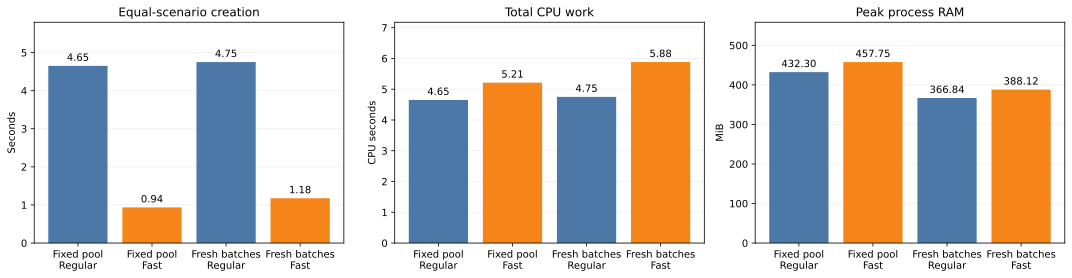

In [6]:
generation_rows = []
for label, _, _ in configurations:
    get = lambda measure: values_for(generation_reports, label, measure)
    generation_rows.append([
        label,
        f"{np.median(get(lambda r: r['memory']['seconds'])):.3f}",
        f"{np.median(get(lambda r: r['cpu_seconds'])):.3f}",
        f"{np.median(get(lambda r: r['memory']['peak_mib'])):.1f}",
        f"{np.median(get(lambda r: r['maximum_dataset_bytes'] / 1024**2)):.3f}",
        f"{np.median(get(lambda r: r['warmup_seconds'])):.3f}",
    ])
show_table(
    ["Configuration", "Wall time (s)", "CPU time (s)", "Peak RAM (MiB)",
     "Largest consumer dataset (MiB)", "Separate warm-up (s)"],
    generation_rows,
)

plot_comparison(generation_reports, [
    ("Equal-scenario creation", "Seconds", lambda r: r["memory"]["seconds"]),
    ("Total CPU work", "CPU seconds", lambda r: r["cpu_seconds"]),
    ("Peak process RAM", "MiB", lambda r: r["memory"]["peak_mib"]),
], "generation_comparison.svg")

**Reading Experiment 1.** Compare Regular with Fast within the same data mode
to measure acceleration. Compare fixed with fresh within the same backend to
measure the storage effect. A consumer dataset is the whole pool or one batch;
the Fast queue and scratch arrays are also counted in process RSS. Bars show
medians over repeats. Compilation/startup costs are separate from warmed timing.

The backends use the same Heston discretization but partition random streams
differently. Equal seeds therefore do not imply identical training scenarios.

## Experiment 2: preparation, training and evaluation

Each configuration is trained in a new process. Within each repeat, initialization,
architecture, instruments, budgets, validation paths and test paths match.
Both CVaR and entropic policies are trained. Simulator warm-up and process startup
are excluded from these elapsed times, matching the memory notebook's protocol.

**Here the optimizer-update budget is equal, not the generated-path count.**
A fixed pool is generated once and reused. Fresh mode generates new batches and
calibration samples throughout training. This experiment tests the practical
runtime/memory trade-off after accounting for that difference.

In [7]:
training_reports = []
order_rng = np.random.default_rng(1701)

for repeat in range(REPEATS):
    current = settings_for_repeat(repeat)
    group = []
    for index in order_rng.permutation(len(configurations)):
        configuration = configurations[index]
        model = make_model(configuration, current)
        report = run_memory_experiment(
            model,
            output_dir=result_dir / "training" / f"repeat_{repeat + 1:02d}",
            verbose=False,
        )
        assert report["data_generator"] == configuration[2]
        report.update(configuration=configuration[0], repeat=repeat + 1)
        group.append(report)
        training_reports.append(report)
    for key in ("comparison_signature", "test_data_id", "instrument_data_ids", "source_hashes", "parameter_count"):
        assert all(r[key] == group[0][key] for r in group), key

# Every repeat uses the same held-out scenarios, even when training seeds differ.
assert len({r["test_data_id"] for r in training_reports}) == 1

(result_dir / "training_reports.json").write_text(
    json.dumps(training_reports, indent=2, allow_nan=False) + "\n"
)

Running Fixed pool / Fast in a fresh process...
Fixed pool / Fast: baseline 384.6 MiB | sampled peak 574.7 MiB | peak increase 190.1 MiB | 6.8 s
Running Fresh batches / Regular in a fresh process...
Fresh batches / Regular: baseline 365.2 MiB | sampled peak 505.6 MiB | peak increase 140.4 MiB | 15.3 s
Running Fresh batches / Fast in a fresh process...
Fresh batches / Fast: baseline 384.4 MiB | sampled peak 517.9 MiB | peak increase 133.5 MiB | 6.1 s
Running Fixed pool / Regular in a fresh process...
Fixed pool / Regular: baseline 365.2 MiB | sampled peak 543.3 MiB | peak increase 178.0 MiB | 10.1 s
Running Fixed pool / Regular in a fresh process...
Fixed pool / Regular: baseline 365.2 MiB | sampled peak 542.5 MiB | peak increase 177.3 MiB | 10.3 s
Running Fresh batches / Regular in a fresh process...
Fresh batches / Regular: baseline 365.2 MiB | sampled peak 502.3 MiB | peak increase 137.1 MiB | 15.0 s
Running Fixed pool / Fast in a fresh process...
Fixed pool / Fast: baseline 384.4 Mi

| Configuration | Preparation + train + test (s) | Peak RAM (MiB) | Retained datasets (MiB) | Test CVaR: mean ± SD | Test entropic risk: mean ± SD |
|---|---|---|---|---|---|
| Fixed pool / Regular | 10.28 | 542.5 | 54.0 | 12.779 ± 0.318 | 45.163 ± 6.788 |
| Fixed pool / Fast | 6.76 | 576.6 | 54.0 | 12.773 ± 0.169 | 50.510 ± 10.617 |
| Fresh batches / Regular | 15.27 | 502.3 | 19.4 | 12.555 ± 0.046 | 45.726 ± 5.215 |
| Fresh batches / Fast | 6.18 | 519.0 | 19.4 | 12.504 ± 0.078 | 43.861 ± 9.713 |

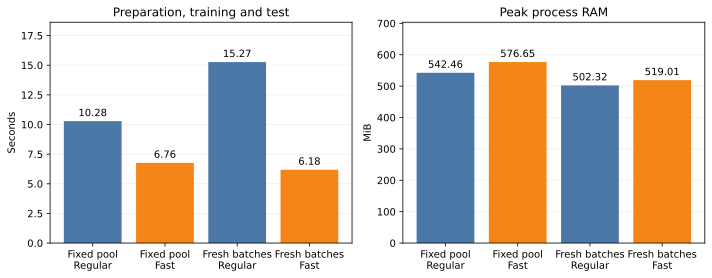

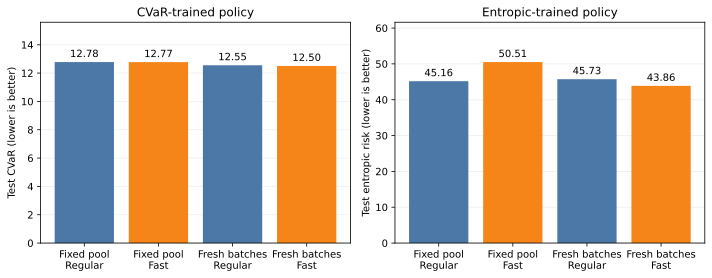

In [8]:
training_rows = []
for label, _, _ in configurations:
    get = lambda measure: values_for(training_reports, label, measure)
    training_rows.append([
        label,
        f"{np.median(get(lambda r: r['memory']['seconds'])):.2f}",
        f"{np.median(get(lambda r: r['memory']['peak_mib'])):.1f}",
        f"{np.median(get(lambda r: r['retained_dataset_mib'])):.1f}",
        mean_sd(get(lambda r: r["test_risk"]["CVaR"]["mean"])),
        mean_sd(get(lambda r: r["test_risk"]["Entropic"]["mean"])),
    ])
show_table(
    ["Configuration", "Preparation + train + test (s)", "Peak RAM (MiB)",
     "Retained datasets (MiB)", "Test CVaR: mean ± SD", "Test entropic risk: mean ± SD"],
    training_rows,
)

plot_comparison(training_reports, [
    ("Preparation, training and test", "Seconds", lambda r: r["memory"]["seconds"]),
    ("Peak process RAM", "MiB", lambda r: r["memory"]["peak_mib"]),
], "training_comparison.svg")

plot_comparison(training_reports, [
    ("CVaR-trained policy", "Test CVaR (lower is better)", lambda r: r["test_risk"]["CVaR"]["mean"]),
    ("Entropic-trained policy", "Test entropic risk (lower is better)", lambda r: r["test_risk"]["Entropic"]["mean"]),
], "test_risks.svg", aggregate=np.mean)

**Reading Experiment 2.** Lower risk is better; each score uses the policy trained
for that objective. Risk tables show mean ± standard deviation across training
seeds, not confidence intervals. The risk bars show means; timing and RAM bars show medians.

Fast generation can also accelerate the fixed-pool baseline. Compare both
backends within each data mode before comparing Fresh/Fast with Fixed/Fast.
The quick profile checks operation and gives preliminary timings; it does not
establish convergence or equivalent hedging quality. More workers can reduce
elapsed time while using similar or greater total CPU work.

In [9]:
summary_rows = []
for prefix in ("Fixed pool", "Fresh batches"):
    regular = f"{prefix} / Regular"
    fast = f"{prefix} / Fast"
    generation_speedup = (
        np.median(values_for(generation_reports, regular, lambda r: r["memory"]["seconds"]))
        / np.median(values_for(generation_reports, fast, lambda r: r["memory"]["seconds"]))
    )
    training_speedup = (
        np.median(values_for(training_reports, regular, lambda r: r["memory"]["seconds"]))
        / np.median(values_for(training_reports, fast, lambda r: r["memory"]["seconds"]))
    )
    summary_rows.append([prefix, f"{generation_speedup:.2f}×", f"{training_speedup:.2f}×"])
show_table(["Data mode", "Path creation speedup: Regular/Fast", "Training experiment speedup: Regular/Fast"], summary_rows)
print(f"Raw reports, logs and figures: {result_dir}")

Raw reports, logs and figures: results/path_generation_comparison/quick


| Data mode | Path creation speedup: Regular/Fast | Training experiment speedup: Regular/Fast |
|---|---|---|
| Fixed pool | 4.97× | 1.52× |
| Fresh batches | 4.04× | 2.47× |